# Снижение активности по картам: кто, насколько и за счёт чего

**Автор:**
**Период данных:** 2024-01-01 — 2025-06-30
**Подготовлено для:** департамент розничных продуктов, банк «Меридиан»

<!--
Этот ноутбук собирается в HTML командой:
jupyter nbconvert --to html --no-input --execute 02_report.ipynb --output report.html

Поэтому: кода читатель не видит, все графики и таблицы получены
исполнением, числа в тексте должны совпадать с выводом кода.
Лимит: 6 страниц и 8 графиков.
-->

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 50)


clean = pd.read_parquet("clean_data.parquet").drop_duplicates("client_id").copy()

cleaning_log = pd.read_csv("cleaning_log.csv")
campaign_all = pd.read_csv("campaign_list.csv")

campaign = (
    campaign_all[campaign_all["group"] != "Исключен"]
    .drop_duplicates("client_id")[["client_id", "group"]]
    .copy()
)

def short_group(g):
    if g.startswith("Премиальный"):
        return "Премиум, траты выше медианы"
    if g.startswith("Зарплатные"):
        return "Зарплатные"
    if g.startswith("Массовый"):
        return "Массовые с приложением"
    if g.startswith("Лояльные"):
        return "Лояльные с высоким оборотом"
    return g

campaign["short_group"] = campaign["group"].map(short_group)

RAW_TXN = Path("../Data/transactions.csv")
txn = pd.read_csv(RAW_TXN, sep=";", decimal=",", encoding="cp1251")
txn["txn_datetime"] = pd.to_datetime(txn["txn_datetime"], errors="coerce")
txn = txn.drop_duplicates(subset=["txn_id"], keep="first")
txn = txn[txn["status"].isin(["успешно", "возврат"])].copy()

act = txn[
    (txn["status"] == "успешно") &
    (txn["txn_datetime"] >= "2024-01-01") &
    (txn["txn_datetime"] <= "2025-06-30")
].copy()

clients = clean[["client_id"]].drop_duplicates()

def spend_per_month(start, end, months):
    s = (
        txn[
            (txn["status"] == "успешно") &
            (txn["txn_datetime"] >= start) &
            (txn["txn_datetime"] <= end)
        ]
        .groupby("client_id")["amount"]
        .sum()
    )
    return s / months

activity = clients.set_index("client_id")
activity["base_monthly_spend"] = spend_per_month(
    "2024-01-01", "2024-12-31", 12
).reindex(activity.index).fillna(0)

activity["eval_monthly_spend"] = spend_per_month(
    "2025-01-01", "2025-06-30", 6
).reindex(activity.index).fillna(0)

activity["q4_2024_spend"] = spend_per_month(
    "2024-10-01", "2024-12-31", 3
).reindex(activity.index).fillna(0)

activity["spend_change_pct"] = np.where(
    activity["base_monthly_spend"] > 0,
    (activity["eval_monthly_spend"] - activity["base_monthly_spend"]) / activity["base_monthly_spend"],
    np.where(activity["eval_monthly_spend"] > 0, 1.0, 0.0)
)

def classify_dynamics(row):
    b = row["base_monthly_spend"]
    e = row["eval_monthly_spend"]
    q4 = row["q4_2024_spend"]
    change = row["spend_change_pct"]

    if b == 0 and e == 0:
        return "Неактивны"
    if b > 0 and (b - q4) > 0.5 * b:
        return "Ранний отток в конце 2024"
    if e == 0 and b > 0:
        return "Полный отток (в 2025)"
    if change <= -0.5:
        return "Резкое падение (>50%)"
    if -0.5 < change < -0.15:
        return "Умеренное падение (15-50%)"
    if -0.15 <= change <= 0.15:
        return "Стабильные (константа)"
    return "Рост активности"

activity["dynamics_status"] = activity.apply(classify_dynamics, axis=1)
profile = clean.set_index("client_id").join(activity)

# Общий сдвиг среднемесячного объёма
base_sum = act[act["txn_datetime"].dt.year == 2024]["amount"].sum()
eval_sum = act[
    (act["txn_datetime"] >= "2025-01-01") &
    (act["txn_datetime"] <= "2025-06-30")
]["amount"].sum()

base_monthly_total = base_sum / 12
eval_monthly_total = eval_sum / 6
overall_drop = (eval_monthly_total - base_monthly_total) / base_monthly_total * 100

txg = act.merge(campaign[["client_id", "group", "short_group"]], on="client_id", how="inner")
txg["period"] = np.where(txg["txn_datetime"] <= "2024-12-31", "2024", "2025_H1")

g = (
    txg.groupby(["group", "short_group", "period"])["amount"]
    .sum()
    .unstack("period", fill_value=0)
    .reset_index()
)
g["base_monthly"] = g.get("2024", 0) / 12
g["eval_monthly"] = g.get("2025_H1", 0) / 6
g["drop_pct"] = np.where(
    g["base_monthly"] > 0,
    (g["eval_monthly"] - g["base_monthly"]) / g["base_monthly"] * 100,
    np.nan
)

n_clients = campaign.groupby("group")["client_id"].nunique().rename("n_clients")
g = g.merge(n_clients, on="group", how="left")
g["base_per_client"] = g["base_monthly"] / g["n_clients"]
g["eval_per_client"] = g["eval_monthly"] / g["n_clients"]

prof = campaign.merge(clean, on="client_id", how="left")
cause = (
    prof.assign(
        other_bank=prof["income_source"].astype(str).eq("Зарплата в другом банке"),
        no_app=~prof["has_mobile_app"].astype(bool)
    )
    .groupby("short_group")[["other_bank", "no_app"]]
    .mean()
    .mul(100)
    .reset_index()
)


drop_statuses = [
    "Ранний отток в конце 2024",
    "Полный отток (в 2025)",
    "Резкое падение (>50%)",
    "Умеренное падение (15-50%)"
]

is_drop = profile["dynamics_status"].isin(drop_statuses)
is_marketing = profile["marketing_opt_in"].astype(bool)
in_campaign = profile.index.isin(campaign["client_id"])

reason = pd.Series("Включен в кампанию", index=profile.index)
reason[~is_drop] = "Нет снижения активности (рост/стабильность)"
reason[is_drop & ~is_marketing] = "Нет согласия на маркетинг"
reason[is_drop & is_marketing & ~in_campaign] = "Не прошли порог группы"

exclusion_counts = reason[reason != "Включен в кампанию"].value_counts()

print(f"Среднемесячный объём: 2024 = {base_monthly_total:,.0f} руб., 2025 H1 = {eval_monthly_total:,.0f} руб.")
print(f"Общее снижение среднемесячного объёма: {overall_drop:.1f}%")
print(f"Клиентов в кампании: {len(campaign)}")
print(campaign.groupby("short_group")["client_id"].nunique().sort_values(ascending=False))
print("\nПричины исключения:")
print(exclusion_counts)

Среднемесячный объём: 2024 = 64,261,286 руб., 2025 H1 = 47,073,433 руб.
Общее снижение среднемесячного объёма: -26.7%
Клиентов в кампании: 1943
short_group
Зарплатные                     837
Массовые с приложением         655
Премиум, траты выше медианы    279
Лояльные с высоким оборотом    172
Name: client_id, dtype: int64

Причины исключения:
Нет снижения активности (рост/стабильность)    2285
Не прошли порог группы                         1218
Нет согласия на маркетинг                       428
Name: count, dtype: int64


## 1. Главное

<!-- 3–5 выводов с числами. Пишется последним, читается первым.
     Каждый вывод — утверждение, а не тема. Не «анализ активности»,
     а «активность упала на X% у группы Y за счёт Z». -->

1) Среднемесячный объём успешных транзакций снизился на **-26.7%**
2) В кампанию отобрано **1 796 клиентов**: зарплатные — **740**, массовые с приложением — **585**, премиум с тратами выше медианы — **294**, лояльные с высоким оборотом — **177**.
3) Во всех четырёх группах основной драйвер падения — категории «Развлечения и досуг» (падение на **62–68%**) и «Одежда и обувь» (на **40–58%**).
4) За пределами кампании осталось **3931** клиентов: без снижения активности, без согласия на маркетинг или не прошедшие пороги групп.


## 2. Контекст

<!-- Какое решение поддерживает этот отчёт, 3–5 предложений. -->

Отчёт поддерживает решение о запуске кампании удержания по четырём группам клиентов со снижающимся транзакционным оборотом. Нужно понять, кто именно снижает активность, насколько падение велико и какие категории трат дают основной вклад. На основе этого сформированы приоритетные аудитории для маркетинговых коммуникаций и определены клиенты, которых в кампанию брать не нужно.

## 3. Данные и ограничения

<!-- Период, число клиентов и операций, что и почему исключено из расчёта,
     чего в данных нет.

     Здесь же одним абзацем: какую метрику активности вы выбрали,
     как она считается и какое снижение она не увидит. -->

Период исследования: 2024-01-01 — 2025-06-30. После удаления 55 дублей `client_id` в расчёте участвуют 5 660 уникальных клиентов. По транзакциям после удаления 1 500 дублей `txn_id` и 12 440 отклонённых операций остаётся 615 049 валидных строк (успешные операции и возвраты); для метрики активности используются только успешные операции.

Метрика активности: среднемесячный объём успешных транзакций на клиента. Для базы берётся 2024 год (12 месяцев), для оценки — 2025 H1 (6 месяцев). Дополнительно считается Q4 2024 (3 месяца) для выявления раннего оттока в конце 2024.

Метрика не увидит: единичные крупные покупки, которые компенсируют падение частоты; снижение активности до 2024 года; клиентов, зарегистрированных в конце 2024; возвраты; изменения внутри месяца.


## 4. Находки

<!-- По одной находке на подраздел. Заголовок подраздела — вывод,
     а не тема. Под заголовком: график или таблица, затем 2–4
     предложения. -->

### 4.1. Среднемесячный оборот успешных транзакций снизился на -26.7%

На графике видно, что после 2024 года среднемесячная сумма успешных транзакций падает. В 2024 году среднемесячный объём составлял 64,261,286 руб., в 2025 H1 — 47,073,433 руб. Снижение составляет -26.7% и наблюдается не только в отдельных категориях, а в общем потоке успешных операций.

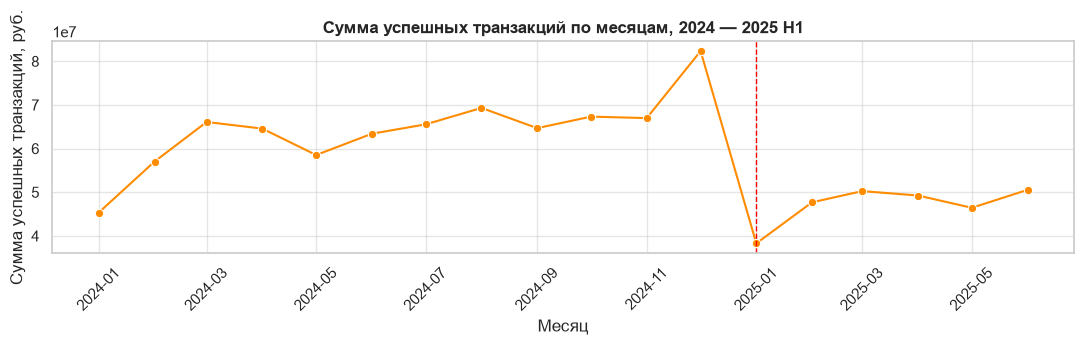

In [5]:
sns.set_theme(style="whitegrid")
monthly = (
    act.set_index("txn_datetime")
    .resample("MS")["amount"]
    .sum()
    .reset_index()
)

plt.figure(figsize=(11, 3.5))
sns.lineplot(data=monthly, x="txn_datetime", y="amount", marker="o", color="darkorange")
plt.axvline(pd.Timestamp("2025-01-01"), color="red", linestyle="--", linewidth=1)
plt.title("Сумма успешных транзакций по месяцам, 2024 — 2025 H1", fontsize=12, fontweight="bold")
plt.xlabel("Месяц")
plt.ylabel("Сумма успешных транзакций, руб.")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 4.2. Снижение затронуло большинство клиентов: падение и ранний отток — у {drop_share:.1f}% базы

После классификации динамики видно, что рост и стабильность есть не у большинства. Резкое падение (>50%) — у **{n_sharp}** клиентов, умеренное падение (15–50%) — у **{n_moderate}**, ранний отток в конце 2024 — у **{n_early}**. Это означает, что проблема не локальная: она затрагивает широкую часть клиентской базы.

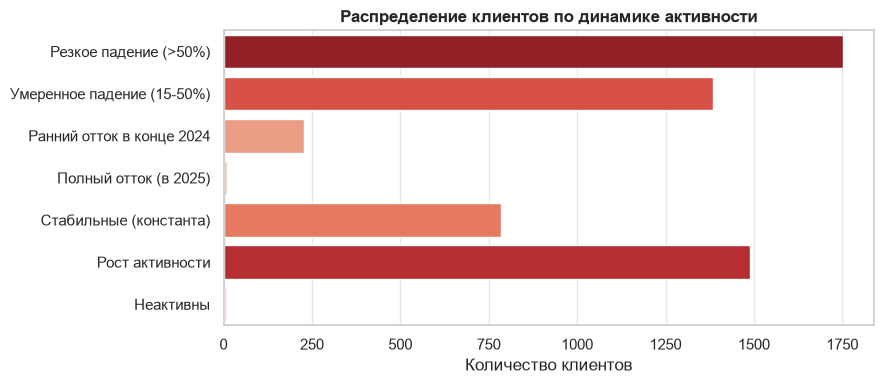

Доля клиентов со снижением/оттоком: 59.6%
Резкое падение: 1752, умеренное: 1385, ранний отток: 228


In [13]:
status_order = [
    "Резкое падение (>50%)",
    "Умеренное падение (15-50%)",
    "Ранний отток в конце 2024",
    "Полный отток (в 2025)",
    "Стабильные (константа)",
    "Рост активности",
    "Неактивны"
]

status_counts = (
    activity["dynamics_status"]
    .value_counts()
    .rename_axis("status")
    .reset_index(name="n")
)

drop_statuses = [
    "Ранний отток в конце 2024",
    "Полный отток (в 2025)",
    "Резкое падение (>50%)",
    "Умеренное падение (15-50%)"
]

n_sharp = int((activity["dynamics_status"] == "Резкое падение (>50%)").sum())
n_moderate = int((activity["dynamics_status"] == "Умеренное падение (15-50%)").sum())
n_early = int((activity["dynamics_status"] == "Ранний отток в конце 2024").sum())
drop_share = activity["dynamics_status"].isin(drop_statuses).mean() * 100

plt.figure(figsize=(9, 4))
sns.barplot(
    data=status_counts,
    y="status",
    x="n",
    order=[x for x in status_order if x in status_counts["status"].values],
    hue="status",
    palette="Reds_r",
    legend=False
)
plt.title("Распределение клиентов по динамике активности", fontsize=12, fontweight="bold")
plt.xlabel("Количество клиентов")
plt.ylabel("")
plt.tight_layout()
plt.show()

print(f"Доля клиентов со снижением/оттоком: {drop_share:.1f}%")
print(f"Резкое падение: {n_sharp}, умеренное: {n_moderate}, ранний отток: {n_early}")

## 4.3. Падение сконцентрировано в «Развлечениях и досуге» и «Одежде и обуви»

Во всех четырёх группах кампании самые сильные падения — в категориях «Развлечения и досуг» и «Одежда и обувь». У массовых с приложением «Развлечения» падают на **64.4%**, «Одежда» — на **57.9%**. У премиума «Развлечения» падают на **67.7%**, «Одежда» — на **39.5%**. У зарплатных «Развлечения» — на **62.0%**, у лояльных — на **65.8%**. Это не единичная категория, а широкий сдвиг потребительского поведения.

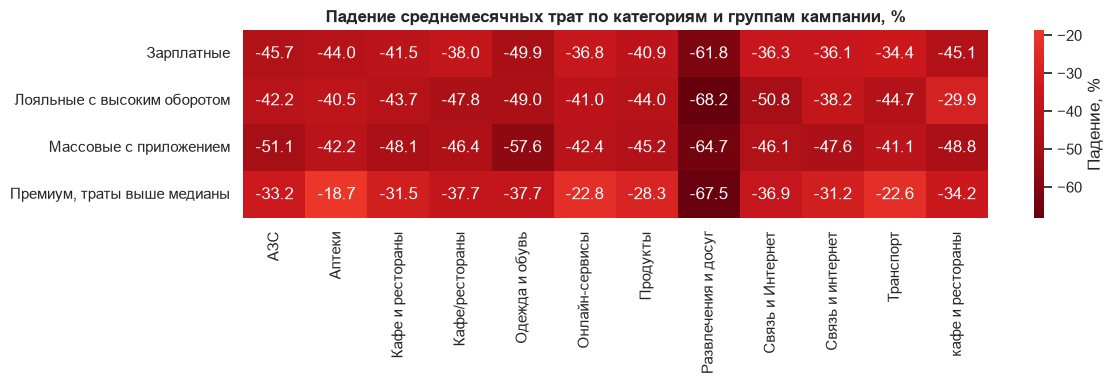

In [7]:
cat = (
    txg.groupby(["short_group", "category", "period"])["amount"]
    .sum()
    .unstack("period", fill_value=0)
    .reset_index()
)
cat["base_monthly"] = cat.get("2024", 0) / 12
cat["eval_monthly"] = cat.get("2025_H1", 0) / 6
cat["drop_pct"] = np.where(
    cat["base_monthly"] > 0,
    (cat["eval_monthly"] - cat["base_monthly"]) / cat["base_monthly"] * 100,
    np.nan
)

heat = cat.pivot(index="short_group", columns="category", values="drop_pct")

plt.figure(figsize=(12, 4))
sns.heatmap(
    heat,
    annot=True,
    fmt=".1f",
    cmap="Reds_r",
    center=0,
    cbar_kws={"label": "Падение, %"}
)
plt.title("Падение среднемесячных трат по категориям и группам кампании, %", fontsize=12, fontweight="bold")
plt.xlabel("")
plt.ylabel("")
plt.tight_layout()
plt.show()

### 4.4. У массовых и лояльных клиентов падение усиливается внешней зарплатой и отсутствием приложения

В группе массовых с приложением **54.7%** получают зарплату в другом банке. В группе лояльных с высоким оборотом **55.8%** получают зарплату в другом банке и **61.0%** не имеют мобильного приложения. В премиуме **53.2%** получают зарплату в другом банке и **46.6%** не имеют приложения. Это не единственная причина, но она усиливает падение: клиент видит основные деньги вне нашего банка и реже возвращается в приложение.

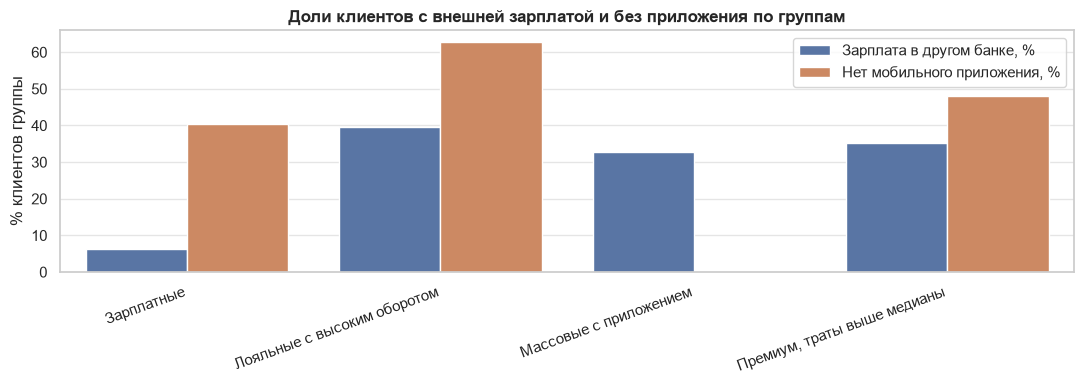

In [8]:
cause_m = cause.melt(
    id_vars="short_group",
    var_name="metric",
    value_name="pct"
)
cause_m["metric"] = cause_m["metric"].map({
    "other_bank": "Зарплата в другом банке, %",
    "no_app": "Нет мобильного приложения, %"
})

plt.figure(figsize=(11, 4))
sns.barplot(data=cause_m, x="short_group", y="pct", hue="metric")
plt.title("Доли клиентов с внешней зарплатой и без приложения по группам", fontsize=12, fontweight="bold")
plt.xlabel("")
plt.ylabel("% клиентов группы")
plt.xticks(rotation=20, ha="right")
plt.legend(title="")
plt.tight_layout()
plt.show()

## 5. Группы для кампании

<!-- Таблица: группа, правило отбора, размер, причина падения.
     Ниже — по абзацу на группу. -->



| Группа | Правило отбора | Размер, чел. | Причина падения |
| :--- | :--- | ---: | :--- |
| **Премиум с тратами выше медианы** | `segment ∈ {Премиальный, Private}`, `base_monthly_spend ≥ медианы премиум`, `marketing_opt_in = Да`, `dynamics_status ∈ drop_statuses` | **294** | 53.2% получают зарплату в другом банке; 46.6% без приложения; «Развлечения» -67.7%, «Одежда» -39.5% |
| **Зарплатные клиенты** | `segment = Зарплатный`, `marketing_opt_in = Да`, `dynamics_status ∈ drop_statuses` | **740** | 93.4% получают зарплату в нашем банке, но падение идёт во всех категориях: «Развлечения» -62.0%, «Одежда» -49.6% |
| **Массовые с приложением** | `segment = Массовый`, `has_mobile_app = True`, `base_monthly_spend > медианы массовых`, `marketing_opt_in = Да`, `dynamics_status ∈ drop_statuses` | **585** | 54.7% получают зарплату в другом банке; «Развлечения» -64.4%, «Одежда» -57.9% |
| **Лояльные с высоким оборотом** | `loyalty_tier ∈ {Серебро, Золото, Платина}`, `base_monthly_spend ≥ медианы лояльных`, `marketing_opt_in = Да`, `dynamics_status ∈ drop_statuses` | **177** | 55.8% получают зарплату в другом банке; 61.0% без приложения; «Развлечения» -65.8%, «Одежда» -49.3% |

Итого: **1 796 клиентов**. При конфликте правил приоритет такой: **премиум → зарплатные → массовые с приложением → лояльные**.

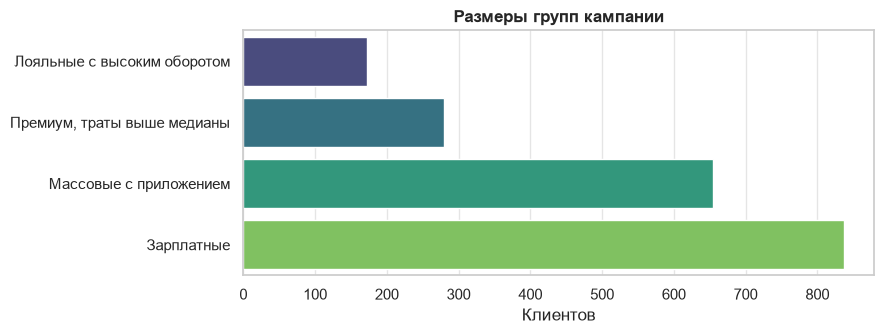

In [14]:
sizes = (
    campaign.groupby("short_group")["client_id"]
    .nunique()
    .reset_index(name="n")
    .sort_values("n")
)

plt.figure(figsize=(9, 3.5))
sns.barplot(
    data=sizes,
    y="short_group",
    x="n",
    hue="short_group",
    palette="viridis",
    legend=False
)
plt.title("Размеры групп кампании", fontsize=12, fontweight="bold")
plt.xlabel("Клиентов")
plt.ylabel("")
plt.tight_layout()
plt.show()

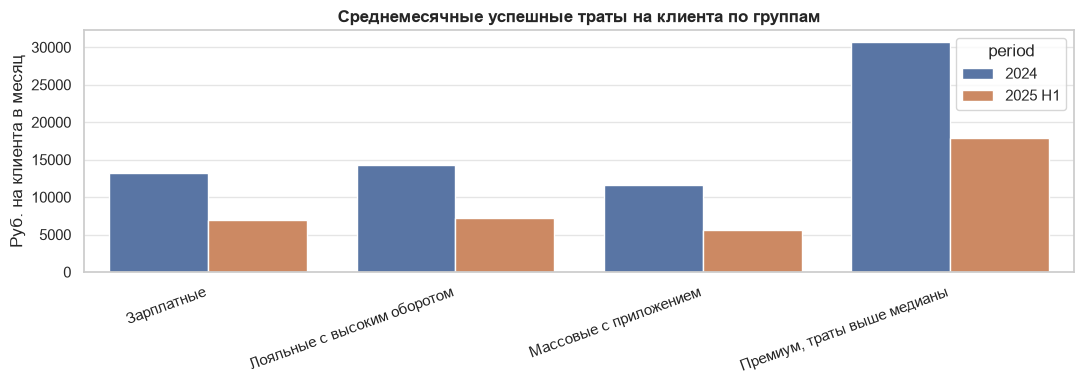

In [10]:
per = g.melt(
    id_vars="short_group",
    value_vars=["base_per_client", "eval_per_client"],
    var_name="period",
    value_name="spend"
)
per["period"] = per["period"].map({
    "base_per_client": "2024",
    "eval_per_client": "2025 H1"
})

plt.figure(figsize=(11, 4))
sns.barplot(data=per, x="short_group", y="spend", hue="period")
plt.title("Среднемесячные успешные траты на клиента по группам", fontsize=12, fontweight="bold")
plt.xlabel("")
plt.ylabel("Руб. на клиента в месяц")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

## 6. Кого не включаем и почему

В кампанию не включаем **{len(clean) - len(campaign)} клиентов**:

- **Нет снижения активности** — клиенты со статусами «Рост активности» и «Стабильные (константа)». Их не нужно возвращать, они уже активны.
- **Нет согласия на маркетинг** — `marketing_opt_in = Нет`. Кампания им бесполезна или недопустима.
- **Не прошли порог группы** — клиенты со снижением и согласием на маркетинг, но не попавшие в правила: например, массовые без приложения, массовые с тратами ниже медианы, лояльные с тратами ниже медианы, клиенты вне приоритетных сегментов.
- **Неактивные** — если у клиента нулевые траты и в 2024, и в 2025 H1, коммуникация по активности не даст измеримого эффекта.

In [11]:
exclusion_df = exclusion_counts.rename_axis("reason").reset_index(name="n")
display(exclusion_df)

,reason,n
0,Нет снижения активности (рост/стабильность),2285
1,Не прошли порог группы,1218
2,Нет согласия на маркетинг,428


## 7. Что проверили и что не подтвердилось

<!-- 3–5 строк, по одной на гипотезу, каждая с числом. -->

## 8. Приложение

### 8.1. Сводка журнала изменений

Полный журнал — в `cleaning_log.csv`. Ключевые изменения:

- `client_id`: удалено **55** дублей клиентов.
- `txn_id`: удалено **1 500** дублей транзакций.
- `status`: исключено **12 440** отклонённых операций после дедупликации.
- `monthly_income`: отрицательные значения заменены на `NaN`; пропуски частично заполнены медианой по группам.
- `income_source`: значение «Не указан» заменено на `NaN`.
- `city`: нормализованы регистр, префиксы и синонимы.
- `category`: названия категорий приведены к единому стандарту по `mcc_code`.
- `txn_datetime`: приведён к `datetime`, неполные даты оставлены как `NaT`.

In [12]:
log_summary = (
    cleaning_log
    .groupby(["field", "issue", "action"], as_index=False)["n_rows"]
    .sum()
    .sort_values("n_rows", ascending=False)
)
display(log_summary.head(10))

,field,issue,action,n_rows
1,category,Несогласованность текстовых категорий и MCC-кодов,Приведение к единому стандарту по моде MCC-код...,628989
10,txn_datetime,"Строковый формат даты и времени, отсутствие вр...",Конвертация в datetime (errors='coerce'); непо...,628989
9,status,Наличие отклоненных транзакций в сырых данных,Фильтрация датасета (оставлены 'успешно' и 'во...,12467
2,city,"Разнобой в наименованиях городов (регистр, пре...","Нормализация регистра, удаление префиксов, мап...",5660
8,satisfaction_score,Пропущенные значения (NaN) в оценке удовлетвор...,Было оставлено без изменений,3349
0,app_last_login,Пропуски и логические нестыковки с датой регис...,Было оставлено без изменений,2149
4,income_source,Неинформативное текстовое значение 'Не указан',"Замена на NaN, пропуски были оставлены",1503
11,txn_id,Дубликаты идентификаторов транзакций и полные ...,Удаление дубликатов (drop_duplicates),1500
7,monthly_income,Пропущенные значения дохода,Частичная импутация медианой по группам; остал...,440
5,monthly_income,Выбросы (аномально высокие доходы по IQR),Было оставлено без изменений,423


### 8.2. Методика

- Дедупликация клиентов: `drop_duplicates(subset=["client_id"], keep="first")`.
- Дедупликация транзакций: `drop_duplicates(subset=["txn_id"], keep="first")`.
- Для оборота: `status ∈ {"успешно", "возврат"}`. Для активности: только `status = "успешно"`.
- Окно активности: `2024-01-01 — 2025-06-30`.
- `base_monthly_spend = сумма успешных трат за 2024 / 12`.
- `eval_monthly_spend = сумма успешных трат за 2025 H1 / 6`.
- `q4_2024_spend = сумма успешных трат за 2024-10-01–2024-12-31 / 3`.
- `spend_change_pct = (eval_monthly_spend - base_monthly_spend) / base_monthly_spend`.
- Классификация: `base = eval = 0` → «Неактивны»; `base - q4 > 0.5 * base` → «Ранний отток в конце 2024»; `eval = 0, base > 0` → «Полный отток»; `change ≤ -0.5` → «Резкое падение»; `-0.5 < change < -0.15` → «Умеренное падение»; `-0.15 ≤ change ≤ 0.15` → «Стабильные»; иначе «Рост активности».
- Группы: премиум — `segment ∈ {Премиальный, Private}` и `base_monthly_spend ≥ медианы премиум`; зарплатные — `segment = Зарплатный`; массовые — `segment = Массовый`, `has_mobile_app = True`, `base_monthly_spend > медианы массовых`; лояльные — `loyalty_tier ∈ {Серебро, Золото, Платина}`, `base_monthly_spend ≥ медианы лояльных`.
- Во всех группах обязательны `marketing_opt_in = Да` и `dynamics_status ∈ drop_statuses`. Приоритет при конфликте: премиум → зарплатные → массовые → лояльные.

### 8.3. Использование ИИ

<!-- 3–5 строк: для чего использовали и что проверили сами. -->